# Problema de la mochila (knapsack 0/1)

Cada objeto tiene un volumen y una importancia (valor). Hay que elegir qué objetos meter, sin pasarse de la capacidad, para maximizar la importancia total. Cada objeto se puede meter una vez como máximo.

La tabla $T[i][c]$ guarda el mejor valor usando los $i$ primeros objetos con capacidad $c$: $T[i][c] = \max(T[i-1][c],\ T[i-1][c - v_i] + w_i)$ si el objeto cabe. Cuesta $O(n \cdot C)$.

## 1. Mochila con tabla

Resolver la mochila para un viaje a la playa y reconstruir qué objetos se eligen.

In [1]:
def mochila(objetos, capacidad):
    n = len(objetos)
    T = [[0] * (capacidad + 1) for _ in range(n + 1)]
    for i, (_, volumen, valor) in enumerate(objetos, 1):
        for c in range(capacidad + 1):
            T[i][c] = T[i - 1][c]
            if volumen <= c:
                T[i][c] = max(T[i][c], T[i - 1][c - volumen] + valor)
    # recorre la tabla hacia atrás para saber qué se eligió
    elegidos, c = [], capacidad
    for i in range(n, 0, -1):
        if T[i][c] != T[i - 1][c]:
            elegidos.append(objetos[i - 1][0])
            c -= objetos[i - 1][1]
    return T[n][capacidad], elegidos[::-1]

# (nombre, volumen, importancia)
playa = [("toalla", 4, 8), ("chanclas", 2, 10), ("sombrilla", 9, 7), ("libro", 3, 4), ("nevera", 8, 9), ("crema", 1, 9)]
print(mochila(playa, 15))

(36, ['toalla', 'chanclas', 'nevera', 'crema'])


## 2. Comprobación y versión con una fila

Comprobar contra fuerza bruta y reducir la memoria a una sola fila recorriendo la capacidad de mayor a menor (así cada objeto se usa una vez).

In [2]:
import random
from itertools import combinations

def mochila_valor(objetos, capacidad):
    fila = [0] * (capacidad + 1)
    for _, volumen, valor in objetos:
        for c in range(capacidad, volumen - 1, -1):
            fila[c] = max(fila[c], fila[c - volumen] + valor)
    return fila[capacidad]

def fuerza_bruta(objetos, capacidad):
    return max(sum(o[2] for o in comb) for r in range(len(objetos) + 1)
               for comb in combinations(objetos, r) if sum(o[1] for o in comb) <= capacidad)

for _ in range(100):
    objs = [(i, random.randint(1, 10), random.randint(1, 20)) for i in range(random.randint(1, 10))]
    cap = random.randint(0, 30)
    assert mochila_valor(objs, cap) == fuerza_bruta(objs, cap) == mochila(objs, cap)[0]
print(mochila_valor(playa, 15))

36


## 3. Mochila ilimitada

Si de cada objeto hay unidades ilimitadas, la fila se recorre de menor a mayor capacidad: así $F[c - v]$ ya puede incluir el mismo objeto, y $F[c] = \max_i (F[c - v_i] + w_i)$. Guardar en cada capacidad el último objeto añadido para reconstruir cuántas unidades se meten de cada uno y comprobarlo contra fuerza bruta.

In [3]:
from collections import Counter

def mochila_ilimitada(objetos, capacidad):
    F, ultimo = [0] * (capacidad + 1), [None] * (capacidad + 1)
    for c in range(1, capacidad + 1):
        for i, (_, volumen, valor) in enumerate(objetos):
            if volumen <= c and F[c - volumen] + valor > F[c]:
                F[c], ultimo[c] = F[c - volumen] + valor, i
    unidades, c = Counter(), capacidad
    while ultimo[c] is not None:
        nombre, volumen, _ = objetos[ultimo[c]]
        unidades[nombre] += 1
        c -= volumen
    return F[capacidad], dict(unidades)

def ilimitada_fuerza_bruta(objetos, capacidad, i=0):
    if i == len(objetos):
        return 0
    _, volumen, valor = objetos[i]
    return max(k * valor + ilimitada_fuerza_bruta(objetos, capacidad - k * volumen, i + 1)
               for k in range(capacidad // volumen + 1))

lingotes = [("oro", 5, 30), ("plata", 3, 14), ("cobre", 2, 7)]
print(mochila_ilimitada(lingotes, 17))

random.seed(16)
for _ in range(300):
    objs = [(i, random.randint(1, 8), random.randint(1, 20)) for i in range(random.randint(1, 4))]
    cap = random.randint(0, 25)
    valor, unidades = mochila_ilimitada(objs, cap)
    assert valor == ilimitada_fuerza_bruta(objs, cap)
    assert sum(objs[i][1] * k for i, k in unidades.items()) <= cap
    assert sum(objs[i][2] * k for i, k in unidades.items()) == valor

(97, {'oro': 3, 'cobre': 1})


## 4. Memoización frente a tabla

Escribir la versión recursiva de arriba abajo `mejor(i, c)` memoizada con `functools.cache` y contar cuántos estados calcula frente a las $(n + 1)(C + 1)$ casillas de la tabla. Probarlo con volúmenes grandes y múltiplos de 100: la memoización solo visita capacidades alcanzables y gana mucho.

In [4]:
import time
from functools import cache

def mochila_memo(objetos, capacidad):
    @cache
    def mejor(i, c):
        if i == 0:
            return 0
        _, volumen, valor = objetos[i - 1]
        sin = mejor(i - 1, c)
        return max(sin, mejor(i - 1, c - volumen) + valor) if volumen <= c else sin
    return mejor(len(objetos), capacidad), mejor.cache_info().currsize

random.seed(17)
for _ in range(200):
    objs = [(i, random.randint(1, 10), random.randint(1, 20)) for i in range(random.randint(1, 10))]
    cap = random.randint(0, 30)
    assert mochila_memo(objs, cap)[0] == fuerza_bruta(objs, cap)

for paso in (1, 100):
    objs = [(i, random.randint(1, 50) * paso, random.randint(1, 100)) for i in range(25)]
    cap = 300 * paso
    inicio = time.perf_counter()
    v_tabla = mochila(objs, cap)[0]
    t_tabla = time.perf_counter() - inicio
    inicio = time.perf_counter()
    v_memo, estados = mochila_memo(objs, cap)
    t_memo = time.perf_counter() - inicio
    assert v_tabla == v_memo
    print(f"C = {cap:>6}: tabla {(len(objs) + 1) * (cap + 1):>8,} casillas en {t_tabla * 1000:7.1f} ms,"
          f" memo {estados:>6,} estados en {t_memo * 1000:5.1f} ms")

C =    300: tabla    7,826 casillas en     0.6 ms, memo  4,987 estados en   1.5 ms
C =  30000: tabla  780,026 casillas en    68.2 ms, memo  5,218 estados en   1.5 ms


## 5. Dibujar la tabla

Dibujar con `matplotlib` la tabla $T[i][c]$ del viaje a la playa como un mapa de calor y marcar las casillas por las que pasa la reconstrucción: cuando el valor cambia respecto a la fila de arriba, el objeto se elige y se salta a la columna $c - v_i$.

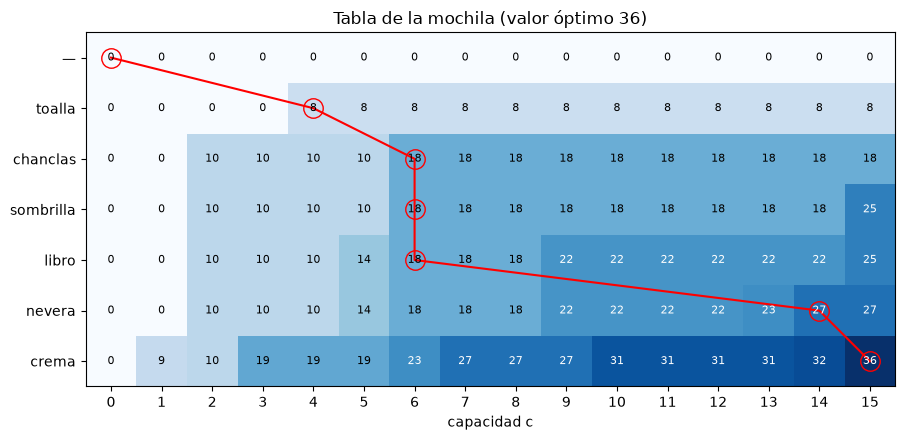

In [5]:
import matplotlib.pyplot as plt

def tabla_mochila(objetos, capacidad):
    T = [[0] * (capacidad + 1) for _ in range(len(objetos) + 1)]
    for i, (_, volumen, valor) in enumerate(objetos, 1):
        for c in range(capacidad + 1):
            T[i][c] = T[i - 1][c]
            if volumen <= c:
                T[i][c] = max(T[i][c], T[i - 1][c - volumen] + valor)
    return T

T = tabla_mochila(playa, 15)
camino, c = [], 15
for i in range(len(playa), 0, -1):
    camino.append((i, c))
    if T[i][c] != T[i - 1][c]:
        c -= playa[i - 1][1]
camino.append((0, c))
assert T[-1][-1] == mochila(playa, 15)[0]

fig, eje = plt.subplots(figsize=(11, 4.5))
eje.imshow(T, cmap="Blues")
for i, fila in enumerate(T):
    for c, valor in enumerate(fila):
        eje.text(c, i, valor, ha="center", va="center", fontsize=8,
                 color="white" if valor > T[-1][-1] * 0.6 else "black")
eje.plot([c for _, c in camino], [i for i, _ in camino], color="red", marker="o", fillstyle="none", markersize=14)
eje.set_xticks(range(16))
eje.set_yticks(range(len(playa) + 1), ["—"] + [nombre for nombre, _, _ in playa])
eje.set(xlabel="capacidad c", title=f"Tabla de la mochila (valor óptimo {T[-1][-1]})")
plt.tight_layout()
plt.show()